# Quantum gyroscopes: Sagnac for light and atoms, in transfer-matrix and qubit notation, down to a CAM toolpath
### SymPy derivations · atom-interferometer gyro · the Heisenberg limit · CAD/CAM of a fiber-gyro coil

**In plain words.** Send two waves around a loop in opposite directions. If the loop rotates,
one wave has farther to go, and the waves come back out of step. This is the **Sagnac effect**,
the principle behind every optical gyroscope in an aircraft. Atoms are waves too, and an atom's
Sagnac phase is about **10¹⁰ times larger** than light's for the same loop. That makes cold atoms
candidates for the gyroscope that limited GPS-free navigation in the previous notebook
(`gps_denied_navigation.ipynb`).

**The plan:**
1. derive Sagnac for light and for matter in SymPy;
2. write the interferometer in modern-physics **transfer-matrix** notation and in **qubit-circuit**
   notation, and show they're the same object;
3. beat the shot-noise limit with entangled atoms (quantum information technology);
4. design a fiber-gyro coil in code: its rotation sensitivity is its area, computed by Green's
   theorem from the **CAD** geometry, which is then exported as a **CAM** toolpath.

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as
well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import quantum_gyroscope as q
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. Sagnac for light

A ring of radius $R$ rotates at $\Omega$. The co-rotating beam has to catch up with a receding
end point: $ct_+=2\pi R+R\Omega t_+$. The counter-rotating beam meets an approaching one:
$ct_-=2\pi R-R\Omega t_-$.

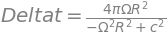

In [2]:
dt_exact, dt_first = q.sagnac_time_symbolic()
display(sp.Eq(sp.Symbol("Delta t"), dt_exact), sp.Eq(sp.Symbol("Delta t (first order, A = pi R^2)"), dt_first))
sp.Eq(sp.Symbol("Delta phi_light"), q.sagnac_phase_light_symbolic())

Only the enclosed **area** matters, not the shape. A coil of $N$ turns multiplies the area by
$N$, which is why fiber-optic gyroscopes wind hundreds of meters to kilometers of fiber.

## 2. Sagnac for matter, via Stokes' theorem

In the rotating frame a particle's canonical momentum gains $m(\boldsymbol\Omega\times\mathbf r)$,
and the extra phase around a closed loop is $\tfrac1\hbar\oint m(\boldsymbol\Omega\times\mathbf r)\cdot d\mathbf l$.
By Stokes' theorem this is $\tfrac{m}{\hbar}\int(\nabla\times(\boldsymbol\Omega\times\mathbf r))\cdot d\mathbf A$.
SymPy computes the curl, and checks it by doing the line integral directly:

In [3]:
curl, circ = q.rotating_frame_circulation_symbolic()
display(sp.Eq(sp.Symbol("curl(Omega x r)"), curl, evaluate=False), sp.Eq(sp.Symbol("loop integral"), circ))
sp.Eq(sp.Symbol("Delta phi_matter"), q.sagnac_phase_matter_symbolic())

                  ⎡ 0 ⎤
                  ⎢   ⎥
curl(Omega x r) = ⎢ 0 ⎥
                  ⎢   ⎥
                  ⎣2⋅Ω⎦

In [4]:
ratio, check = q.matter_light_ratio_symbolic()
display(sp.Eq(sp.Symbol("phi_matter / phi_light"), ratio)); print("ratio - m c^2/(2 hbar omega) =", check)
for name, m in (("Rb-87 vs 780 nm light", q.M_RB87), ("Cs-133 vs 780 nm light", q.M_CS133)):
    print(f"{name}: gain = {q.matter_light_gain(m, 780e-9):.2e}")

ratio - m c^2/(2 hbar omega) = 0
Rb-87 vs 780 nm light: gain = 2.55e+10
Cs-133 vs 780 nm light: gain = 3.89e+10


The derived factor is $mc^2/(2\hbar\omega)$. Popular accounts often drop the 2; the order of
magnitude, about $10^{10}$, is the point. The catch is that atom interferometers enclose tiny
areas (square millimeters or less, against square meters for a fiber coil) and count about
$10^6$ atoms, against about $10^{15}$ photons. §4 does the full comparison.

## 3. The atom-interferometer gyroscope: the accelerometer plus Coriolis

The previous notebook derived the three-pulse phase $\phi=k_{\text{eff}}[x(0)-2x(T)+x(2T)]$. In a
rotating frame an atom moving at $\mathbf v$ feels the Coriolis acceleration $-2\boldsymbol\Omega\times\mathbf v$.
Feeding that into the same formula:

In [5]:
sp.Eq(sp.Symbol("phi_gyro"), q.atom_gyro_phase_symbolic())

In [6]:
v, T = 10.0, 0.01
A = q.atom_gyro_area(v, T)
print(f"atoms at v = {v} m/s, T = {T*1e3:.0f} ms: enclosed area = {A*1e6:.2f} mm^2")
print(f"Earth-rate phase: {q.atom_gyro_phase(q.OMEGA_EARTH, v, T):.3f} rad   "
      f"(matter-Sagnac formula with that area: {q.sagnac_phase_matter(A, q.OMEGA_EARTH, q.M_RB87):.3f} rad)")

atoms at v = 10.0 m/s, T = 10 ms: enclosed area = 11.77 mm^2
Earth-rate phase: 2.349 rad   (matter-Sagnac formula with that area: 2.349 rad)


Two derivations, one number. The Coriolis picture and the matter-Sagnac area picture agree
exactly, which is a strong consistency check on both.

## 4. Light vs atoms, honestly: scale factor × √(particles)

Rotation resolution per shot is $\delta\Omega=1/(C\sqrt N\,S)$, where $S=d\phi/d\Omega$ is the scale
factor, $N$ the number of detected particles, and $C$ the fringe contrast.

In [7]:
S_fog = 8*np.pi*1.0*(np.pi*0.05**2) / (1550e-9*q.C) * (1000/(2*np.pi*0.05))   # 1 km fiber on a 5 cm radius coil
S_ai = q.atom_gyro_phase(1.0, 10.0, 0.01)                                           # phase per rad/s
rows = [("fiber gyro, 1 km, R = 5 cm", S_fog, 1e15, 1.0), ("atom gyro, v=10 m/s, T=10 ms", S_ai, 1e6, 0.5),
        ("atom gyro, T=100 ms", q.atom_gyro_phase(1.0, 10.0, 0.1), 1e6, 0.5)]
for name, S, N, Cc in rows:
    d = q.gyro_sensitivity(S, N, Cc)
    print(f"{name:32s} S = {S:9.3e} s   N = {N:.0e}   per-shot = {d:.2e} rad/s = {q.deg_per_hour(d):.2e} deg/h")
print(f"\nEarth rate = {q.deg_per_hour(q.OMEGA_EARTH):.2f} deg/h")

fiber gyro, 1 km, R = 5 cm       S = 1.352e+00 s   N = 1e+15   per-shot = 2.34e-08 rad/s = 4.82e-03 deg/h
atom gyro, v=10 m/s, T=10 ms     S = 3.221e+04 s   N = 1e+06   per-shot = 6.21e-08 rad/s = 1.28e-02 deg/h
atom gyro, T=100 ms              S = 3.221e+06 s   N = 1e+06   per-shot = 6.21e-10 rad/s = 1.28e-04 deg/h

Earth rate = 15.04 deg/h


The atoms' huge per-particle scale factor is offset by their small number. In practice,
mature fiber gyros and atom gyros land in comparable ranges. The atom's advantage is long-term
**stability**: the scale factor is set by fundamental constants (ħ, the atom's mass, the laser
wavelength), not by a coil that expands with temperature. That stability, not raw resolution,
is what slows down navigation drift.

## 5. Two notations, one interferometer

**Transfer-matrix notation** (modern physics and optics) treats a 50/50 beam splitter as
$B=\tfrac1{\sqrt2}\begin{pmatrix}1&i\\i&1\end{pmatrix}$ and a path phase as $P(\phi)=\mathrm{diag}(e^{i\phi},1)$.
A Mach–Zehnder interferometer, optical or atomic, is the product $BP(\phi)B$:

In [8]:
M, P = q.mach_zehnder_symbolic()
display(sp.Eq(sp.Symbol("B P B"), M, evaluate=False))
print("port probabilities:", P)
print("unitary (M^dag M = I):", sp.simplify(M.H * M) == sp.eye(2))

        ⎡   ⅈ⋅φ          ⎛ ⅈ⋅φ    ⎞⎤
        ⎢  ℯ      1    ⅈ⋅⎝ℯ    + 1⎠⎥
        ⎢  ──── - ─    ────────────⎥
        ⎢   2     2         2      ⎥
B P B = ⎢                          ⎥
        ⎢  ⎛ ⅈ⋅φ    ⎞         ⅈ⋅φ  ⎥
        ⎢ⅈ⋅⎝ℯ    + 1⎠    1   ℯ     ⎥
        ⎢────────────    ─ - ────  ⎥
        ⎣     2          2    2    ⎦

port probabilities: [1/2 - cos(phi)/2, cos(phi)/2 + 1/2]
unitary (M^dag M = I): True


**Qubit notation** (QIS): the two paths are $|0\rangle$ and $|1\rangle$, the beam splitter is a
Hadamard gate, and the phase is $R_z(\phi)$. The circuit is $H\,R_z(\phi)\,H$:

In [9]:
print("H Rz(phi) H |0> gives P(0), P(1) =", q.mz_port_probabilities_qubit())
print("probs(B P B) - probs(X H Rz H) =", q.mz_equals_qubit_circuit().tolist())

H Rz(phi) H |0> gives P(0), P(1) = [cos(phi/2)**2, sin(phi/2)**2]


probs(B P B) - probs(X H Rz H) = [[0, 0], [0, 0]]


The two descriptions agree once the output ports are relabeled (an $X$ gate). **Dictionary:**

| optics / modern physics | quantum information |
|---|---|
| two paths / two ports | basis states $|0\rangle,|1\rangle$ |
| 50/50 beam splitter $B$ | Hadamard $H$ (up to fixed phases) |
| path-length phase $P(\phi)$ | $R_z(\phi)$ |
| detector click at port $j$ | measure in the computational basis |
| fringe $\tfrac12(1\pm\cos\phi)$ | $|\langle j|HR_zH|0\rangle|^2$ |
| Sagnac / Coriolis phase | the unknown parameter to estimate |

## 6. Quantum information technology: beating $1/\sqrt N$

$N$ independent atoms give quantum Fisher information $F_Q=N$, so $\delta\phi\ge1/\sqrt N$:
the **shot-noise limit**. Put the $N$ atoms in a GHZ state
$(|0\cdots0\rangle+|1\cdots1\rangle)/\sqrt2$, and the whole state picks up $N\phi$. That gives
$F_Q=N^2$ and $\delta\phi\ge1/N$: the **Heisenberg limit**. The QFI below is computed numerically
from the state vectors:

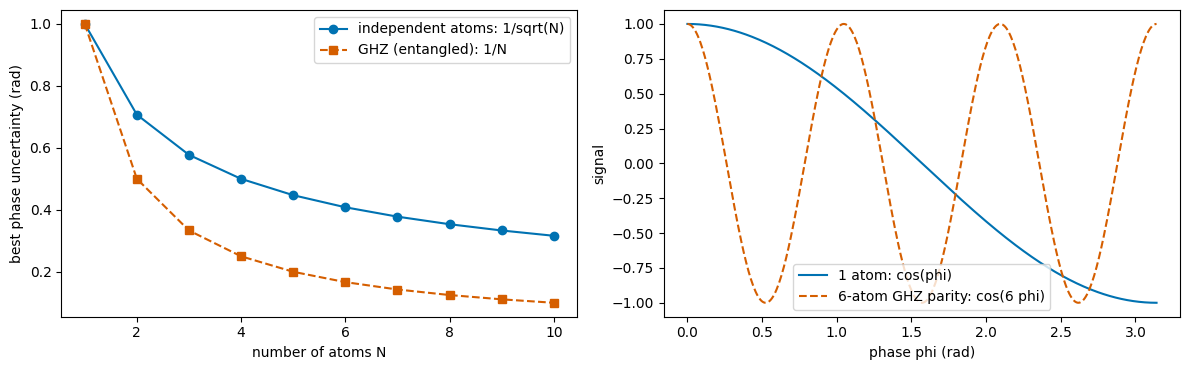

Figure description: left, phase uncertainty versus atom number; independent atoms (circles, solid) fall as 1/sqrt(N), GHZ states (squares, dashed) fall faster as 1/N. Right, the 6-atom GHZ parity fringe (dashed) oscillates six times faster than the single-atom fringe (solid), so it is steeper and more sensitive.


In [10]:
ns_ = np.arange(1, 11)
Fp = [q.quantum_fisher_information(q.product_phase_state, n) for n in ns_]
Fg = [q.quantum_fisher_information(q.ghz_phase_state, n) for n in ns_]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ns_, 1/np.sqrt(Fp), "o-", label="independent atoms: 1/sqrt(N)")
ax[0].plot(ns_, 1/np.sqrt(Fg), "s--", label="GHZ (entangled): 1/N")
ax[0].set_xlabel("number of atoms N"); ax[0].set_ylabel("best phase uncertainty (rad)"); ax[0].legend()
ph = np.linspace(0, np.pi, 400)
ax[1].plot(ph, np.cos(ph), "-", label="1 atom: cos(phi)")
ax[1].plot(ph, q.ghz_parity_fringe(6, ph), "--", label="6-atom GHZ parity: cos(6 phi)")
ax[1].set_xlabel("phase phi (rad)"); ax[1].set_ylabel("signal"); ax[1].legend(); plt.tight_layout(); plt.show()
print("Figure description: left, phase uncertainty versus atom number; independent atoms (circles, solid) fall as "
      "1/sqrt(N), GHZ states (squares, dashed) fall faster as 1/N. Right, the 6-atom GHZ parity fringe (dashed) "
      "oscillates six times faster than the single-atom fringe (solid), so it is steeper and more sensitive.")

The catch is **decoherence** (see `dephasing_phase_retrieval.ipynb`). A GHZ state dephases
$N$ times faster too, so the advantage survives only while the entangled state stays coherent.
That trade-off is the engineering problem of quantum-enhanced sensors.

## 7. CAD → physics → CAM: designing a Sagnac coil

The scale factor is $8\pi A_{\text{eff}}/(\lambda c)$, so the **geometry is the instrument**.
Take a flat Archimedean spiral waveguide or fiber groove, $r=r_0+p\,\theta/2\pi$, closed by a
straight return lead. Its effective Sagnac area is the winding-weighted area, which Green's
theorem gives directly from the polygon of the toolpath (the shoelace formula):

$$A=\tfrac12\oint(x\,dy-y\,dx)=\tfrac12\sum_i(x_iy_{i+1}-x_{i+1}y_i).$$

SymPy gives the exact spiral area for comparison:

In [11]:
r0s, ps, Ns = sp.symbols("r_0 p N", positive=True)
A_sym = q.spiral_area_symbolic()
display(sp.Eq(sp.Symbol("A_eff"), A_sym))
r0, pitch, turns = 0.020, 0.0005, 20          # 20 mm inner radius, 0.5 mm pitch, 20 turns
xy = q.spiral_path(r0, pitch, turns, pts_per_turn=720)
A_cad = q.shoelace_area(xy); A_exact = float(A_sym.subs({r0s: r0, ps: pitch, Ns: turns}))
print(f"A from CAD polygon (shoelace) = {A_cad:.6f} m^2   exact = {A_exact:.6f} m^2   rel diff {abs(A_cad-A_exact)/A_exact:.1e}")
print(f"groove length = {q.path_length(xy):.3f} m   scale factor at 1550 nm = {q.coil_scale_factor(xy):.3e} s")
print(f"Earth-rate Sagnac phase = {q.coil_scale_factor(xy)*q.OMEGA_EARTH:.2e} rad")

A from CAD polygon (shoelace) = 0.039793 m^2   exact = 0.039794 m^2   rel diff 1.3e-05
groove length = 3.152 m   scale factor at 1550 nm = 2.152e-03 s
Earth-rate Sagnac phase = 1.57e-07 rad


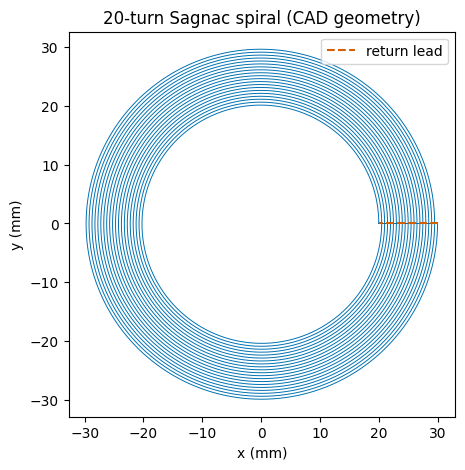

Figure description: a flat 20-turn Archimedean spiral from 20 mm to 30 mm radius, with a dashed straight return lead from the outer end back to the start.


In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(xy[:, 0]*1e3, xy[:, 1]*1e3, lw=0.7, color=OI[0])
ax.plot(*(xy[[-2, -1]]*1e3).T, "--", color=OI[1], label="return lead")
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)"); ax.legend(loc="upper right")
ax.set_title("20-turn Sagnac spiral (CAD geometry)"); plt.show()
print("Figure description: a flat 20-turn Archimedean spiral from 20 mm to 30 mm radius, with a dashed straight "
      "return lead from the outer end back to the start.")

### Export: DXF (CAD), SVG, and G-code (CAM)

The same coordinates become a DXF that CAD programs can open, an SVG for documentation, and a
G-code toolpath that engraves the groove (millimeters, absolute coordinates, one plunge, one
continuous cut, retract). Each file is read back and compared with the original geometry.

In [13]:
out = pathlib.Path.cwd().parent / "hardware" / "sagnac_coil"; out.mkdir(parents=True, exist_ok=True)
xy_cam = q.spiral_path(r0, pitch, turns, pts_per_turn=180)   # coarser path for the machine
dxf = q.to_dxf(xy_cam); (out / "sagnac_coil.dxf").write_text(dxf)
(out / "sagnac_coil.svg").write_text(q.to_svg(xy_cam))
gcode, L_mm = q.to_gcode(xy_cam, depth_mm=0.15, feed_mm_min=300)
(out / "sagnac_coil.gcode").write_text(gcode)
segs = q.read_dxf_lines(dxf); moves = q.gcode_moves(gcode)
print("DXF segments:", len(segs), " max |DXF - path| =", np.max(np.abs(segs[:, :2] - xy_cam[:-1]*1e3)), "mm")
print("G-code moves:", len(moves), " max |G-code - path| =", np.max(np.abs(moves - xy_cam[1:]*1e3)), "mm")
print(f"cut length {L_mm/1e3:.3f} m at 300 mm/min -> machining time {L_mm/300:.1f} min")
print("area from the CAM path:", f"{q.shoelace_area(xy_cam):.6f} m^2 (vs {A_exact:.6f} exact)")
print("\nfirst lines of G-code:"); print("\n".join(gcode.splitlines()[:8]))
print("\nfiles:", sorted(p.name for p in out.iterdir()))

DXF segments: 3601  max |DXF - path| = 4.9977626516373164e-05 mm
G-code moves: 3601  max |G-code - path| = 4.9977626516373164e-05 mm
cut length 3.151 m at 300 mm/min -> machining time 10.5 min
area from the CAM path: 0.039785 m^2 (vs 0.039794 exact)

first lines of G-code:
(Sagnac coil groove -- generated by dgs.quantum_gyroscope)
G21 (mm)
G90 (absolute)
G0 Z2.000
G0 X20.0000 Y0.0000
G1 Z-0.150 F60
G1 X19.9906 Y0.6981 F300
G1 X19.9568 Y1.3955

files: ['sagnac_coil.dxf', 'sagnac_coil.gcode', 'sagnac_coil.svg']


The coarser machining path still reproduces the area, and with it the scale factor, to
about 2×10⁻⁴ relative error. Coordinates are written to 0.1 µm, far finer than any machine can cut.
So the CAD-to-CAM pipeline preserves the physics.

To reach navigation grade, scale the same design up: about 1 km of fiber on a 5 cm coil
(§4). Real gyroscopes also control thermal gradients, backscatter, and polarization, which is
where the engineering effort goes.

## 8. Summary

| quantity | value |
|---|---|
| light Sagnac | $8\pi A\Omega/(\lambda c)$ |
| matter Sagnac | $2mA\Omega/\hbar$ (Stokes: curl of $\Omega\times r$ is $2\Omega$) |
| matter/light gain | $mc^2/(2\hbar\omega)\approx2.5\times10^{10}$ (Rb, 780 nm) |
| atom gyro | $\phi=2k_{\text{eff}}v\Omega T^2$, Coriolis in the accelerometer formula |
| notation | $BP(\phi)B$ ≡ $X\,H R_z(\phi) H$ |
| entanglement | QFI $N\to N^2$: $1/\sqrt N\to1/N$ |
| CAD → CAM | shoelace area = Sagnac area, preserved in DXF and G-code |

**Connections to the rest of the repo:**
* the phase readout is the fringe-retrieval problem of `gps_denied_navigation` and `gs_core`;
* decoherence limits on GHZ states are in `cell_hilbert_bridge` and `dephasing_phase_retrieval`;
* Green's theorem is Griffiths Ch. 1.

*Synthetic numbers; civilian education.*